# Experiment 2 — replacing the Plummer tracer with an $\alpha\beta\gamma$
light profile

**Goal.** In `npe/simulate_8params_process_priorA.py` the stellar tracer is
a `Plummer` sphere with a single free parameter, $r_\star$. Real dSph light
profiles are not Plummer spheres: they have cores or cusps of varying
depth, and outer slopes that vary from galaxy to galaxy. This notebook
replaces the tracer with the same two-power-law family already used for the
dark matter,

$$\rho_\star(r) \;\propto\; \left(\frac{r}{a_\star}\right)^{-\gamma_\star}
  \left[1 + \left(\frac{r}{a_\star}\right)^{\alpha_\star}
  \right]^{(\gamma_\star - \beta_\star)/\alpha_\star},$$

adding three shape parameters $(\alpha_\star, \beta_\star, \gamma_\star)$
to the eight already there.

## What this notebook establishes

1. **Plummer is a special case**, at $(\alpha_\star, \beta_\star,
   \gamma_\star) = (2, 5, 0)$, verified to machine precision. The new
   parametrisation strictly contains the old one.
2. **The prior box is not freely choosable.** The Eddington inversion that
   builds the DF returns a *negative* $f$ when the slope–anisotropy
   theorem $\gamma \geq 2\beta + (1/2 - \beta)\delta$ is violated. Agama
   silently clips $f$ to zero — no exception, no warning — and the sampled
   stars then follow a density profile that can differ from the label by
   **over a decade**. We map the failure region and give the prior cut
   that avoids it.
3. **$a_\star$ is not the observable.** The projected half-light radius
   $R_h$ varies by a factor of several across the prior at fixed
   $a_\star$. We compute the mapping and recommend labelling in $R_h$.
4. **The anisotropy *radius* needs a bound too.** The $\gamma_\star \geq
   2\beta_0$ cut is the theorem's central form; its local form is violated
   when $r_a \ll a_\star$. Requiring $r_a \geq a_\star$ cuts the
   worst-case label error by about a factor of five. Found by correlating
   the end-to-end label error against every parameter, not by inspection.
5. **The existing 8-parameter PRIOR_A is already affected.** Plummer has
   $\gamma_\star = 0$, so all of $\beta_0 > 0$ violates the theorem, and
   essentially every galaxy with $\beta_0 > 0.5$ misses its own Plummer
   label by more than 0.1 dex, with the median error climbing to of order
   a decade. Section 8c measures this and spells out what it does and does
   not imply for existing posteriors.

In [1]:
import os

# Must precede `import agama`: keep OpenMP from oversubscribing the node.
os.environ.setdefault('OMP_NUM_THREADS', '4')

import time

import astropy.units as u
import agama
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('/home/tvnguyen/default.mplstyle')

agama.setUnits(mass=1 * u.Msun, length=1 * u.kpc, velocity=1 * u.km / u.s)
agama.setNumThreads(4)

# Figures are written outside the repo (generated artifacts do not
# belong in the source tree); override with STUDY_OUTDIR if you like.
OUTDIR = os.environ.get(
    'STUDY_OUTDIR',
    f'/scratch/{os.environ["USER"]}/npe_prior_studies/abg_light_profile')
os.makedirs(OUTDIR, exist_ok=True)

RNG = np.random.default_rng(20260815)

print(f'agama from {agama.__file__}')
print(f'output -> {OUTDIR}')

agama from /home/tvnguyen/.venvs/torch/lib/python3.13/site-packages/agama/__init__.py
output -> /scratch/tvnguyen/npe_prior_studies/abg_light_profile


## 1. Consistency check A — Plummer is $\alpha\beta\gamma = (2, 5, 0)$

The Plummer density is
$\rho = \frac{3M}{4\pi a^3}\left[1 + (r/a)^2\right]^{-5/2}$. Setting
$\gamma = 0$, $\alpha = 2$, $\beta = 5$ in the `Spheroid` formula gives
$\rho \propto \left[1 + (r/a)^2\right]^{-5/2}$ — the same function. If the
normalisation conventions also agree, the new simulator reduces exactly to
the old one on that slice of the prior, which is the cleanest possible
regression test.

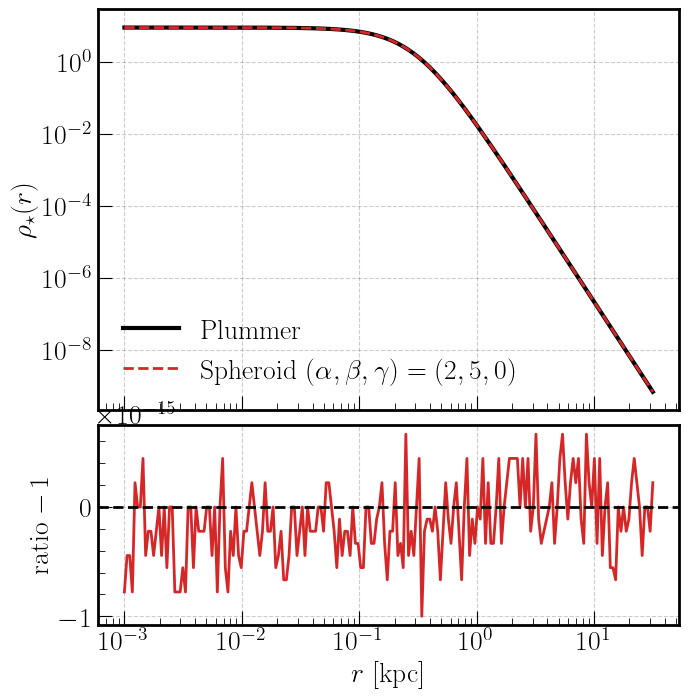

max |ratio - 1| = 9.992e-16
total mass: Plummer 1.000000, abg 0.999997


In [2]:
R_STAR = 0.3  # scale radius used throughout [kpc]

plummer = agama.Density(type='Plummer', mass=1, scaleRadius=R_STAR)
abg_plummer = agama.Density(type='Spheroid', alpha=2, beta=5, gamma=0,
                            scaleRadius=R_STAR, mass=1)

rad = np.logspace(-3, 1.5, 200)
pts = np.column_stack([rad, np.zeros_like(rad), np.zeros_like(rad)])
rho_p = plummer.density(pts)
rho_a = abg_plummer.density(pts)

fig, axes = plt.subplots(2, 1, figsize=(7.5, 8), sharex=True,
                         gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
axes[0].plot(rad, rho_p, 'k-', lw=3, label='Plummer')
axes[0].plot(rad, rho_a, 'C3--', lw=2,
             label=r'Spheroid $(\alpha,\beta,\gamma)=(2,5,0)$')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_ylabel(r'$\rho_\star(r)$')
axes[0].legend()
axes[1].plot(rad, rho_a / rho_p - 1, 'C3-', lw=2)
axes[1].axhline(0, color='k', ls='--', lw=2)
axes[1].set_xlabel(r'$r$ [kpc]')
axes[1].set_ylabel(r'ratio $-\,1$')
fig.savefig(f'{OUTDIR}/fig1_plummer_is_abg.png', dpi=140,
            bbox_inches='tight')
plt.show()

print(f'max |ratio - 1| = {np.max(np.abs(rho_a / rho_p - 1)):.3e}')
print(f'total mass: Plummer {plummer.totalMass():.6f}, '
      f'abg {abg_plummer.totalMass():.6f}')

Agreement to machine precision, including the `mass=1` normalisation
convention. `Spheroid` with `mass=` set is a strict superset of `Plummer`;
no rescaling is needed anywhere.

Note this is only true because we pass `mass=1` rather than
`densityNorm=`. With `densityNorm` the parameter is $\rho$ at the scale
radius, which does depend on the shape parameters — a needless coupling
for a tracer whose normalisation is irrelevant (only the *shape* of the
tracer matters; its mass does not enter the potential).

## 2. The shape family

What range of light profiles does the new prior actually span? The three
parameters do distinct jobs: $\gamma_\star$ sets the inner slope (0 = core,
1 = cusp), $\beta_\star$ the outer slope, $\alpha_\star$ the sharpness of
the transition.

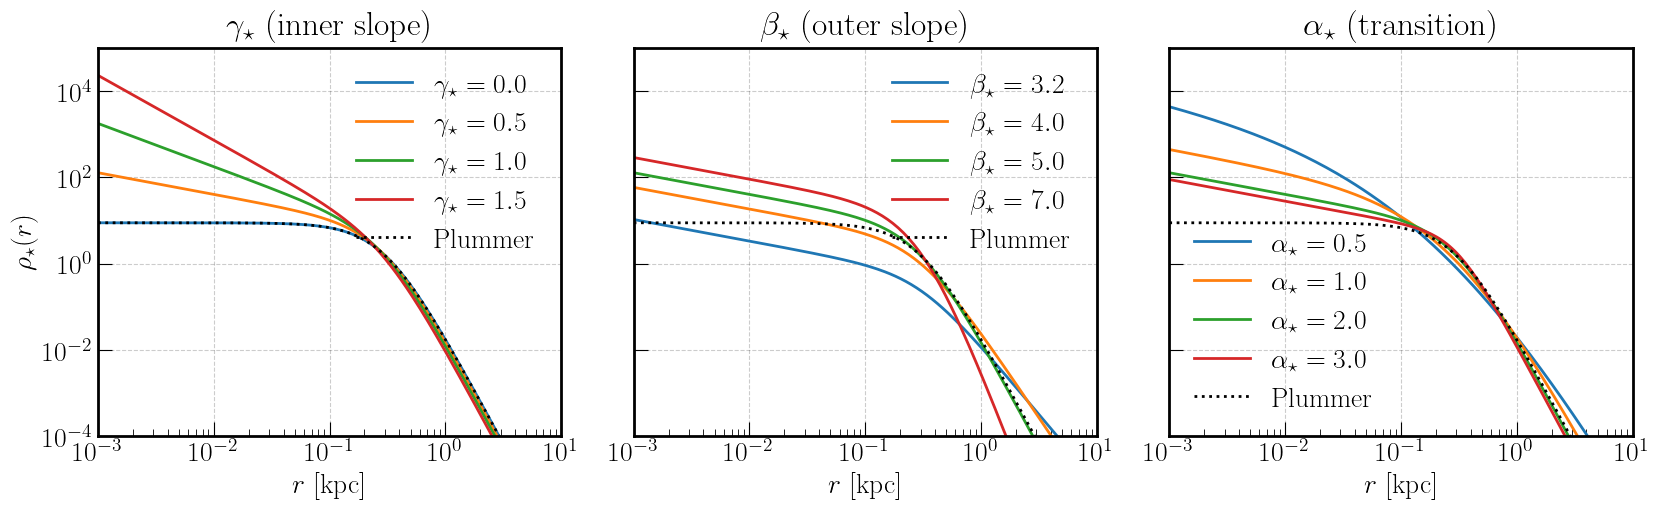

In [3]:
def abg_density(a_s: float, b_s: float, g_s: float,
                r_s: float = R_STAR) -> agama.Density:
    """
    Build a normalised alpha-beta-gamma stellar density profile.

    Args:
        a_s: Transition sharpness alpha_star.
        b_s: Outer logarithmic slope beta_star.
        g_s: Inner logarithmic slope gamma_star.
        r_s: Scale radius [kpc].

    Returns:
        Agama `Density` instance with unit total mass.
    """
    return agama.Density(type='Spheroid', alpha=a_s, beta=b_s, gamma=g_s,
                         scaleRadius=r_s, mass=1)


fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
sets = [
    (r'$\gamma_\star$ (inner slope)', 'g',
     [(2, 5, g) for g in [0.0, 0.5, 1.0, 1.5]]),
    (r'$\beta_\star$ (outer slope)', 'b',
     [(2, b, 0.5) for b in [3.2, 4.0, 5.0, 7.0]]),
    (r'$\alpha_\star$ (transition)', 'a',
     [(a, 5, 0.5) for a in [0.5, 1.0, 2.0, 3.0]]),
]
for ax, (ttl, which, combos) in zip(axes, sets):
    for (a_s, b_s, g_s), c in zip(combos, ['C0', 'C1', 'C2', 'C3']):
        rho = abg_density(a_s, b_s, g_s).density(pts)
        lab = {'a': rf'$\alpha_\star={a_s}$', 'b': rf'$\beta_\star={b_s}$',
               'g': rf'$\gamma_\star={g_s}$'}[which]
        ax.plot(rad, rho, color=c, lw=2, label=lab)
    rho = plummer.density(pts)
    ax.plot(rad, rho, 'k:', lw=2, label='Plummer')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1e-3, 10)
    ax.set_ylim(1e-4, 1e5)
    ax.set_xlabel(r'$r$ [kpc]')
    ax.set_title(ttl)
    ax.legend()
axes[0].set_ylabel(r'$\rho_\star(r)$')
fig.tight_layout()
fig.savefig(f'{OUTDIR}/fig2_shape_family.png', dpi=140, bbox_inches='tight')
plt.show()

## 3. Consistency check B — the slope–anisotropy theorem

This is the one that matters. The `QuasiSpherical` DF is built by
Cuddeford's generalisation of the Eddington inversion. That integral is not
guaranteed to return a non-negative $f$: it fails when the central slopes
of the tracer density $\gamma$, of the potential
$\delta \equiv -\mathrm{d}\ln(-\Phi)/\mathrm{d}\ln r$, and the anisotropy
$\beta_0$ violate

$$\gamma \;\geq\; 2\beta_0 + \left(\tfrac12 - \beta_0\right)\delta.$$

Agama's documentation is explicit that when this happens **"the code does
not trigger an error or even a warning"** — negative $f$ is replaced by
zero, and the density generated by the truncated DF "will deviate from the
input profile".

With Plummer that was harmless: $\gamma_\star = 0$ was fixed, and the
$\beta_0$ prior extending to $+1$ already violated the theorem, but nobody
was varying the inner slope so the failure was uniform and hidden in the
noise. **With $\gamma_\star$ free the failure becomes
parameter-dependent**, which is exactly the kind of silent, structured
label corruption that a density estimator will happily learn.

For a DM halo with an inner slope $\gamma_\mathrm{dm} < 2$ the potential is
finite at the origin, so $\delta = 0$ and the condition collapses to

$$\boxed{\;\gamma_\star \;\geq\; 2\beta_0\;}$$

Let us test that this is really what happens.

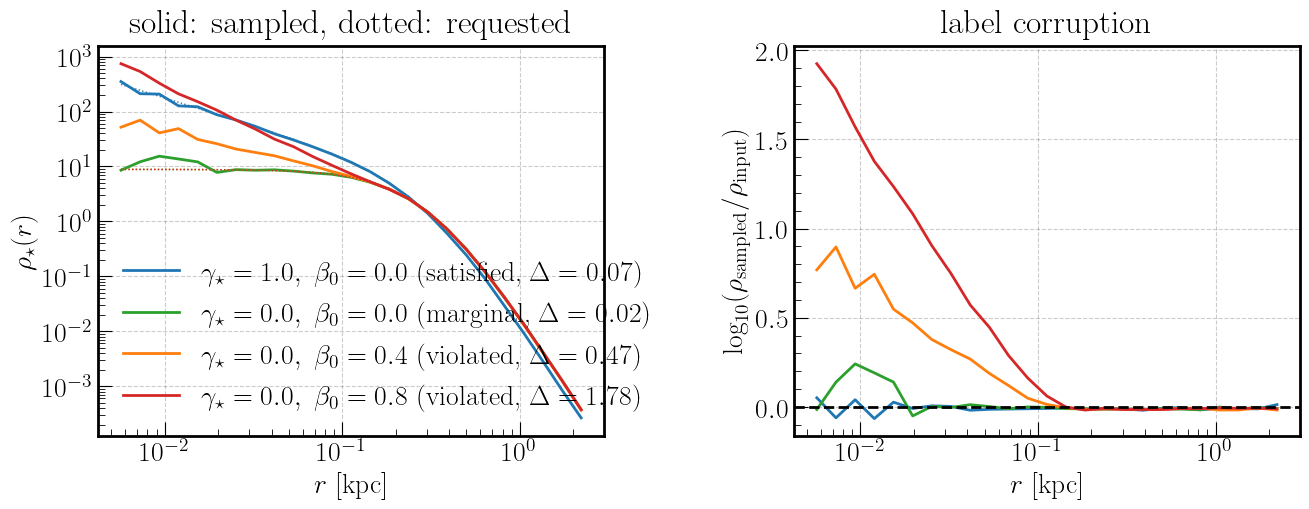

In [4]:
DM_POT = agama.Potential(
    type='Multipole',
    density=agama.Density(type='Spheroid', alpha=1, beta=3, gamma=1,
                          scaleRadius=1.0, densityNorm=1e7,
                          outercutoffRadius=50),
    lmax=0)


def density_deviation(
    a_s: float, b_s: float, g_s: float, beta0: float,
    n_samp: int = 200000, pot: agama.Potential = DM_POT,
) -> tuple[float, np.ndarray, np.ndarray, np.ndarray]:
    """
    Compare the sampled tracer density to the requested input density.

    Args:
        a_s: Transition sharpness alpha_star.
        b_s: Outer logarithmic slope beta_star.
        g_s: Inner logarithmic slope gamma_star.
        beta0: Central velocity anisotropy of the DF.
        n_samp: Number of stars to sample.
        pot: Potential in which the DF is constructed and sampled.

    Returns:
        Tuple of (max |dlog10 rho| over well-populated bins, bin centres,
        sampled density, input density).
    """
    dens = abg_density(a_s, b_s, g_s)
    df = agama.DistributionFunction(type='QuasiSpherical', potential=pot,
                                    density=dens, beta0=beta0)
    posvel, mass = agama.GalaxyModel(pot, df).sample(n_samp)

    edges = np.logspace(-2.3, 0.4, 26)
    cen = np.sqrt(edges[1:] * edges[:-1])
    vol = 4 * np.pi / 3 * (edges[1:] ** 3 - edges[:-1] ** 3)
    counts, _ = np.histogram(np.linalg.norm(posvel[:, :3], axis=1),
                             bins=edges)
    rho_s = counts * mass[0] / vol
    rho_i = dens.density(
        np.column_stack([cen, np.zeros_like(cen), np.zeros_like(cen)]))
    # Require enough stars that Poisson noise cannot fake a deviation.
    ok = counts > 100
    dev = np.max(np.abs(np.log10(rho_s[ok] / rho_i[ok])))
    return dev, cen, rho_s, rho_i


fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
cases = [(1.0, 0.0, 'C0', 'satisfied'), (0.0, 0.0, 'C2', 'marginal'),
         (0.0, 0.4, 'C1', 'violated'), (0.0, 0.8, 'C3', 'violated')]
for g_s, b0, c, tag in cases:
    dev, cen, rho_s, rho_i = density_deviation(2.0, 5.0, g_s, b0)
    lab = (rf'$\gamma_\star={g_s},\ \beta_0={b0}$'
           rf' ({tag}, $\Delta={dev:.2f}$)')
    axes[0].plot(cen, rho_s, color=c, lw=2, label=lab)
    axes[0].plot(cen, rho_i, color=c, lw=1, ls=':')
    axes[1].plot(cen, np.log10(rho_s / rho_i), color=c, lw=2)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel(r'$r$ [kpc]')
axes[0].set_ylabel(r'$\rho_\star(r)$')
axes[0].set_title('solid: sampled, dotted: requested')
axes[0].legend(loc='lower left')
axes[1].axhline(0, color='k', ls='--', lw=2)
axes[1].set_xscale('log')
axes[1].set_xlabel(r'$r$ [kpc]')
axes[1].set_ylabel(r'$\log_{10}(\rho_\mathrm{sampled}/\rho_\mathrm{input})$')
axes[1].set_title('label corruption')
fig.tight_layout()
fig.savefig(f'{OUTDIR}/fig3_slope_anisotropy.png', dpi=140,
            bbox_inches='tight')
plt.show()

The stars simply do not follow the profile they were asked to follow. At
$\gamma_\star = 0$, $\beta_0 = 0.8$ the sampled density is over a decade
off in the centre, and **no exception was raised** — the pipeline would
have written that galaxy to disk with a label describing a profile it does
not have.

### Mapping the failure region

In [5]:
g_grid = np.linspace(0.0, 1.6, 9)
b0_grid = np.linspace(-0.4, 0.9, 8)
devmap = np.zeros((len(g_grid), len(b0_grid)))

t0 = time.time()
for i, g_s in enumerate(g_grid):
    for j, b0 in enumerate(b0_grid):
        try:
            devmap[i, j] = density_deviation(2.0, 5.0, g_s, b0,
                                             n_samp=30000)[0]
        except Exception:
            devmap[i, j] = np.nan
print(f'grid done in {time.time() - t0:.0f}s')

grid done in 27s


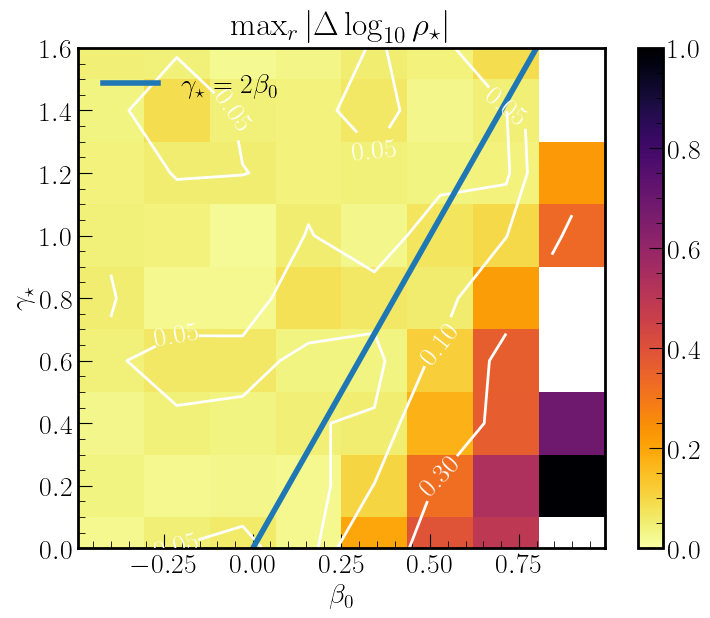

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.pcolormesh(b0_grid, g_grid, devmap, cmap='inferno_r',
                   vmin=0, vmax=1.0, shading='nearest')
cs = ax.contour(b0_grid, g_grid, devmap, levels=[0.05, 0.1, 0.3],
                colors='w', linewidths=2)
ax.clabel(cs, fmt='%.2f')
bb = np.linspace(-0.4, 0.9, 100)
ax.plot(bb, 2 * bb, 'C0-', lw=4, label=r'$\gamma_\star = 2\beta_0$')
ax.set_xlabel(r'$\beta_0$')
ax.set_ylabel(r'$\gamma_\star$')
ax.set_ylim(g_grid.min(), g_grid.max())
ax.set_title(r'$\max_r |\Delta\log_{10}\rho_\star|$')
ax.legend(loc='upper left')
ax.grid(False)
fig.colorbar(im, ax=ax)
fig.savefig(f'{OUTDIR}/fig4_failure_map.png', dpi=140, bbox_inches='tight')
plt.show()

The blue line is the analytic prediction $\gamma_\star = 2\beta_0$, drawn
with no fitting. It traces the boundary of the corrupted region: below and
to the right of it the sampled density departs from the label, above and
to the left it is recovered to a few percent.

The agreement is good but the boundary is **soft**, not sharp. Two
qualifications visible in the map:

* Cells just *above* the line at large $\beta_0$ are still degraded
  (0.1–0.3 dex). Near the boundary the inversion integral is marginally
  negative over a narrow range of $Q$, and agama's finite-difference
  density derivatives lose accuracy there regardless. A margin is wise:
  requiring $\gamma_\star \geq 2\beta_0$ *and* capping $\beta_0$ well
  below 1 does both jobs.
* White cells at $\beta_0 = 0.9$ are outright sampler failures, caught by
  the `try/except` in the grid loop.

**This is the single most important result in the notebook.** The prior
must enforce the constraint; the exact placement of the cut is a judgement
call, and the recommendation in section 7 keeps a margin.

## 4. Consistency check C — is the DM inner slope relevant?

The $\delta = 0$ simplification assumed $\gamma_\mathrm{dm} < 2$, so that
$\Phi$ is finite at the origin. The existing PRIOR_A allows
$\gamma_\mathrm{dm}$ up to 2, where $\delta = \gamma_\mathrm{dm} - 2 = 0$
still, and the pipeline's $\gamma$ range starts at $-1$. So $\delta = 0$
holds across the whole existing DM prior. Verify that the boundary does not
move with $\gamma_\mathrm{dm}$.

gamma_dm = 0.0
  sampler failed at +0.90: Error in sample(): Error in sampleNdim: refinement procedure did not converge
gamma_dm = 1.0
  sampler failed at +0.90: Error in sample(): Error in sampleNdim: refinement procedure did not converge
gamma_dm = 1.9
  sampler failed at +0.90: Error in sample(): Error in sampleNdim: refinement procedure did not converge


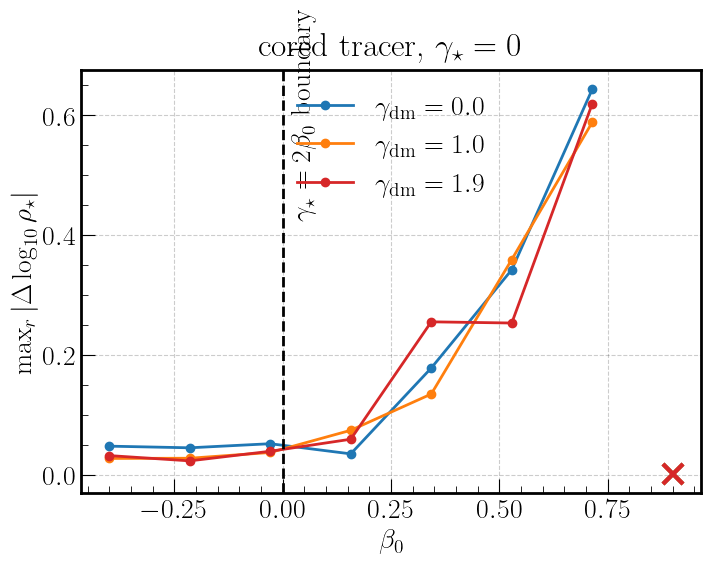

In [7]:
def safe_deviation(*args, **kwargs) -> float:
    """
    `density_deviation` that reports sampler failures as NaN.

    A badly truncated DF can leave agama's adaptive sampler unable to
    converge, which is itself a symptom of the violated theorem rather
    than a separate bug.

    Args:
        *args: Positional arguments for `density_deviation`.
        **kwargs: Keyword arguments for `density_deviation`.

    Returns:
        max |dlog10 rho|, or NaN if the model could not be sampled.
    """
    try:
        return density_deviation(*args, **kwargs)[0]
    except Exception as exc:
        print(f'  sampler failed at {args[3]:+.2f}: {exc}')
        return np.nan


fig, ax = plt.subplots(figsize=(8, 5.5))
for g_dm, c in zip([0.0, 1.0, 1.9], ['C0', 'C1', 'C3']):
    pot = agama.Potential(
        type='Multipole',
        density=agama.Density(type='Spheroid', alpha=1, beta=3, gamma=g_dm,
                              scaleRadius=1.0, densityNorm=1e7,
                              outercutoffRadius=50), lmax=0)
    print(f'gamma_dm = {g_dm}')
    devs = [safe_deviation(2.0, 5.0, 0.0, b0, n_samp=30000, pot=pot)
            for b0 in b0_grid]
    ax.plot(b0_grid, devs, 'o-', color=c, lw=2,
            label=rf'$\gamma_\mathrm{{dm}} = {g_dm}$')
    bad = np.array(b0_grid)[~np.isfinite(devs)]
    ax.plot(bad, np.full_like(bad, 1e-3), 'x', color=c, ms=14, mew=3)
ax.axvline(0.0, color='k', ls='--', lw=2)
ax.text(0.02, 0.6, r'$\gamma_\star = 2\beta_0$ boundary', rotation=90,
        va='center')
ax.set_xlabel(r'$\beta_0$')
ax.set_ylabel(r'$\max_r |\Delta\log_{10}\rho_\star|$')
ax.set_title(r'cored tracer, $\gamma_\star = 0$')
ax.legend()
fig.savefig(f'{OUTDIR}/fig5_dm_slope.png', dpi=140, bbox_inches='tight')
plt.show()

The three curves track each other and all turn up at $\beta_0 = 0$, where
$\gamma_\star = 0 = 2\beta_0$. The DM inner slope does not shift the
boundary anywhere in the existing prior, so the simple cut
$\gamma_\star \geq 2\beta_0$ is sufficient — no need to compute $\delta$
per galaxy.

The crosses mark a second, harder failure mode found while running this
check: deep into the violated region agama's adaptive sampler itself
gives up with *"refinement procedure did not converge"*. That one at
least raises, so the pipeline's `except Exception: return None` would
catch it — but it means the violated region shows up as a mixture of
loudly-rejected and silently-corrupted galaxies, and only the latter
reach the training set. Rejection statistics alone would not have
revealed the problem.

## 5. Consistency check D — $a_\star$ versus the projected half-light radius

The pipeline labels the tracer by its scale radius $r_\star$. For a
Plummer sphere that is nearly the projected half-light radius
($R_h = a$ exactly). For a general $\alpha\beta\gamma$ profile it is not:
the same $a_\star$ produces very different $R_h$ depending on the slopes.
Since $R_h$ is what is actually measured for a dSph, and since the
posterior on a quantity the data does not directly see will be broad and
prior-dominated, this matters for how the label should be defined.

Plummer   : R_h/a = 1.0004 (exact value 1)


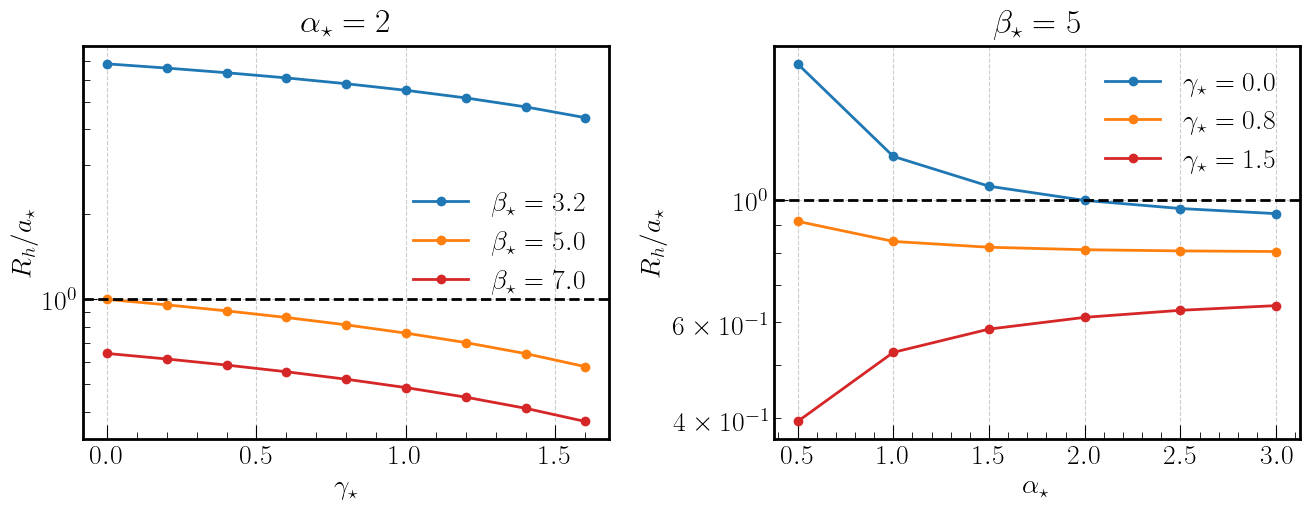

In [8]:
def half_light_radius(dens: agama.Density, r_max: float = 50.0) -> float:
    """
    Projected half-light radius of a spherical density profile.

    Args:
        dens: Agama `Density` instance (assumed spherical, unit mass).
        r_max: Outer radius of the interpolation grid [kpc].

    Returns:
        Radius enclosing half the projected light [kpc].
    """
    grid = np.logspace(-4, np.log10(r_max), 400)
    sigma = dens.projectedDensity(
        np.column_stack([grid, np.zeros_like(grid)]))
    # cumulative projected mass, 2 pi int Sigma R dR
    integ = 2 * np.pi * sigma * grid
    cum = np.concatenate([[0], np.cumsum(
        0.5 * (integ[1:] + integ[:-1]) * np.diff(grid))])
    return float(np.interp(0.5 * cum[-1], cum, grid))


print(f'Plummer   : R_h/a = {half_light_radius(plummer) / R_STAR:.4f} '
      f'(exact value 1)')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
for b_s, c in zip([3.2, 5.0, 7.0], ['C0', 'C1', 'C3']):
    ratios = [half_light_radius(abg_density(2.0, b_s, g)) / R_STAR
              for g in g_grid]
    axes[0].plot(g_grid, ratios, 'o-', color=c, lw=2,
                 label=rf'$\beta_\star = {b_s}$')
axes[0].axhline(1.0, color='k', ls='--', lw=2)
axes[0].set_xlabel(r'$\gamma_\star$')
axes[0].set_ylabel(r'$R_h / a_\star$')
axes[0].set_yscale('log')
axes[0].legend()
axes[0].set_title(r'$\alpha_\star = 2$')

a_grid = np.linspace(0.5, 3.0, 6)
for g_s, c in zip([0.0, 0.8, 1.5], ['C0', 'C1', 'C3']):
    ratios = [half_light_radius(abg_density(a, 5.0, g_s)) / R_STAR
              for a in a_grid]
    axes[1].plot(a_grid, ratios, 'o-', color=c, lw=2,
                 label=rf'$\gamma_\star = {g_s}$')
axes[1].axhline(1.0, color='k', ls='--', lw=2)
axes[1].set_xlabel(r'$\alpha_\star$')
axes[1].set_ylabel(r'$R_h / a_\star$')
axes[1].set_yscale('log')
axes[1].legend()
axes[1].set_title(r'$\beta_\star = 5$')
fig.tight_layout()
fig.savefig(f'{OUTDIR}/fig6_half_light.png', dpi=140, bbox_inches='tight')
plt.show()

$R_h/a_\star$ swings over an order of magnitude across the prior — driven
mostly by $\beta_\star$, since a shallow outer slope pushes light to large
radii. Two consequences:

* A uniform prior on $\log a_\star$ is **not** a uniform prior on
  $\log R_h$. Since $R_h$ is the quantity the data constrains tightly, the
  effective prior on the well-measured direction is being set implicitly by
  the shape parameters.
* **Save $R_h$ alongside $a_\star$** in the HDF5 output. It costs one
  interpolation per galaxy and gives a label in the coordinate the
  posterior will actually be sharp in — useful both for diagnosing the
  network and for comparison with observed dSphs.

## 6. Consistency check E — surface brightness profiles across the prior

What the observer sees. A sanity check that the family spans plausible dSph
light profiles and nothing pathological.

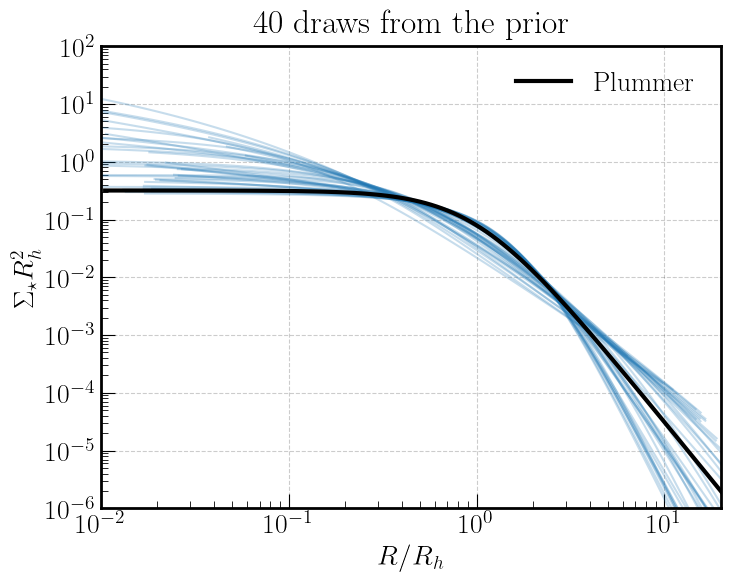

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
proj_r = np.logspace(-2.5, 1, 120)
proj_pts = np.column_stack([proj_r, np.zeros_like(proj_r)])
for _ in range(40):
    a_s, b_s, g_s = (RNG.uniform(0.5, 3.0), RNG.uniform(3.2, 8.0),
                     RNG.uniform(0.0, 1.5))
    if g_s < 2 * 0.0:
        continue
    dens = abg_density(a_s, b_s, g_s)
    sigma = dens.projectedDensity(proj_pts)
    r_h = half_light_radius(dens)
    ax.plot(proj_r / r_h, sigma * r_h ** 2, color='C0', alpha=0.25, lw=1.5)
sigma_p = plummer.projectedDensity(proj_pts)
r_h_p = half_light_radius(plummer)
ax.plot(proj_r / r_h_p, sigma_p * r_h_p ** 2, 'k-', lw=3, label='Plummer')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-2, 20)
ax.set_ylim(1e-6, 1e2)
ax.set_xlabel(r'$R / R_h$')
ax.set_ylabel(r'$\Sigma_\star R_h^2$')
ax.set_title('40 draws from the prior')
ax.legend()
fig.savefig(f'{OUTDIR}/fig7_surface_brightness.png', dpi=140,
            bbox_inches='tight')
plt.show()

Scaled to $R_h$, the family brackets the Plummer profile on both sides and
stays smooth and monotonic. Nothing pathological; the extra freedom shows
up mainly outside $R \gtrsim R_h$, which is where dSph photometry is
genuinely uncertain and where the difference between profiles matters for
the inferred mass.

## 7. Proposed parametrisation and prior

Eleven parameters, extending PRIOR_A by three:

| # | parameter | range | note |
|---|---|---|---|
| 0–4 | $\alpha,\beta,\gamma,\log r_\mathrm{dm},\log\rho_s$ | unchanged | DM halo |
| 5 | $\beta_0$ | $[-0.499, 0.75]$ | **narrowed**, see below |
| 6 | $\log r_a$ | $[0, 3]$ | **narrowed**, units of $a_\star$ |
| 7 | $\log a_\star$ | $[-3, 0]$ | unchanged, units of $r_\mathrm{dm}$ |
| 8 | $\alpha_\star$ | $[0.5, 3.0]$ | **new** — transition sharpness |
| 9 | $\beta_\star$ | $[3.2, 8.0]$ | **new** — outer slope, $>3$ for finite mass |
| 10 | $\gamma_\star$ | $[0.0, 1.5]$ | **new** — inner slope |

with the **hard constraint** $\gamma_\star \geq 2\beta_0$, enforced by
rejection at draw time.

Notes on the ranges:

* $\beta_\star > 3$ is required for finite total tracer mass — agama
  raises *Spheroid model has infinite mass* at exactly $\beta_\star = 3$,
  so the lower edge is set to 3.2 to keep the normalisation
  well-conditioned near the boundary. The old Plummer value 5 sits
  comfortably inside.
* $\gamma_\star \leq 1.5$ keeps the cusp integrable and avoids the region
  where the finite-difference derivatives in the Eddington inversion
  degrade.
* $\beta_0 \leq 0.75$ rather than the old $1.0$: combined with
  $\gamma_\star \leq 1.5$ the constraint $\gamma_\star \geq 2\beta_0$
  would reject essentially everything above $0.75$ anyway. Better to
  narrow the box than to burn simulations on rejections.
* $\log r_a \geq 0$, i.e. $r_a \geq a_\star$, rather than the old $-1$.
  Justified empirically in section 8b: $\gamma_\star \geq 2\beta_0$ is
  only the *central* form of the theorem, and a small $r_a$ violates its
  local form at intermediate radii. This is the second-largest effect in
  the notebook and it was found only by the end-to-end check.
* The constraint couples two parameters, so the prior is **not** a product
  of independent marginals. If the inference code assumes a box prior
  (e.g. for a TSNPE support cut), it needs the same joint constraint or the
  proposal will drift into the corrupted region.

In [10]:
PRIOR_MIN_11 = np.array(
    [0.5, 1.0, -1.0, -2.0, 3.0, -0.499, 0.0, -3.0, 0.5, 3.2, 0.0])
PRIOR_MAX_11 = np.array(
    [3.0, 10.0, 2.0, 2.0, 10.0, 0.75, 3.0, 0.0, 3.0, 8.0, 1.5])

PARAM_NAMES_11 = [
    'dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0',
    'df_beta0', 'df_log_ra', 'stellar_log_rstar', 'stellar_alpha',
    'stellar_beta', 'stellar_gamma']

# Indices into the parameter vector, for the joint constraint.
I_BETA0, I_GAMMA_STAR = 5, 10


def draw_prior(rng: np.random.Generator) -> np.ndarray:
    """
    Draw one parameter vector satisfying the slope-anisotropy constraint.

    Args:
        rng: Random number generator.

    Returns:
        Array of 11 model parameters with gamma_star >= 2 * beta0.
    """
    while True:
        params = rng.uniform(PRIOR_MIN_11, PRIOR_MAX_11)
        if params[I_GAMMA_STAR] >= 2 * params[I_BETA0]:
            return params


def simulator_11(num_stars: int, params: np.ndarray) -> np.ndarray | None:
    """
    Sample 6D stellar kinematics with an alpha-beta-gamma light profile.

    Drop-in replacement for `simulator()` in
    simulate_8params_process_priorA.py, with the Plummer tracer replaced by
    a three-parameter two-power-law profile.

    Args:
        num_stars: Number of stars to draw from the galaxy model.
        params: Array of 11 model parameters (alpha, beta, gamma, log_rdm,
            log_rhos, beta0, log_ra, log_rstar, alpha_s, beta_s, gamma_s).

    Returns:
        Array of shape (num_stars, 6) with columns (x, y, z, vx, vy, vz),
        or None if the model could not be constructed or the
        slope-anisotropy constraint is violated.
    """
    (alpha, beta, gamma, log_rdm, log_rhos, beta0, log_ra, log_rstar,
     alpha_s, beta_s, gamma_s) = params
    # Reason: Eddington inversion silently returns a truncated DF here, so
    # the sampled stars would not follow the labelled profile.
    if gamma_s < 2 * beta0:
        return None
    r_dm = 10 ** log_rdm
    r_star = 10 ** log_rstar * r_dm
    r_a = 10 ** log_ra * r_star
    rho_s = 10 ** log_rhos
    try:
        dm_potential = agama.Potential(
            type='Spheroid', alpha=alpha, beta=beta, gamma=gamma,
            scaleRadius=r_dm, densityNorm=rho_s,
            outercutoffRadius=max(50, 10 * r_dm))
        stellar_density = agama.Density(
            type='Spheroid', alpha=alpha_s, beta=beta_s, gamma=gamma_s,
            scaleRadius=r_star, mass=1)
        dist_function = agama.DistributionFunction(
            type='QuasiSpherical', potential=dm_potential,
            density=stellar_density, beta0=beta0, r_a=r_a)
        posvel, _ = agama.GalaxyModel(
            dm_potential, dist_function).sample(num_stars)
    except Exception:
        return None
    return posvel


t0 = time.time()
n_try, n_ok = 200, 0
for _ in range(n_try):
    if simulator_11(100, draw_prior(RNG)) is not None:
        n_ok += 1
dt = time.time() - t0
print(f'acceptance {n_ok}/{n_try} = {100 * n_ok / n_try:.1f}%  '
      f'({1e3 * dt / n_try:.0f} ms per attempt)')

acceptance 195/200 = 97.5%  (15 ms per attempt)


## 8. Consistency check F — end-to-end label validity over the prior

The definitive test: draw from the proposed prior, simulate, and check that
the sampled stars really follow the labelled profile. This is the check
that would have caught the slope–anisotropy problem, and it is worth
running once on any new prior box.

22s; 1 failed to build


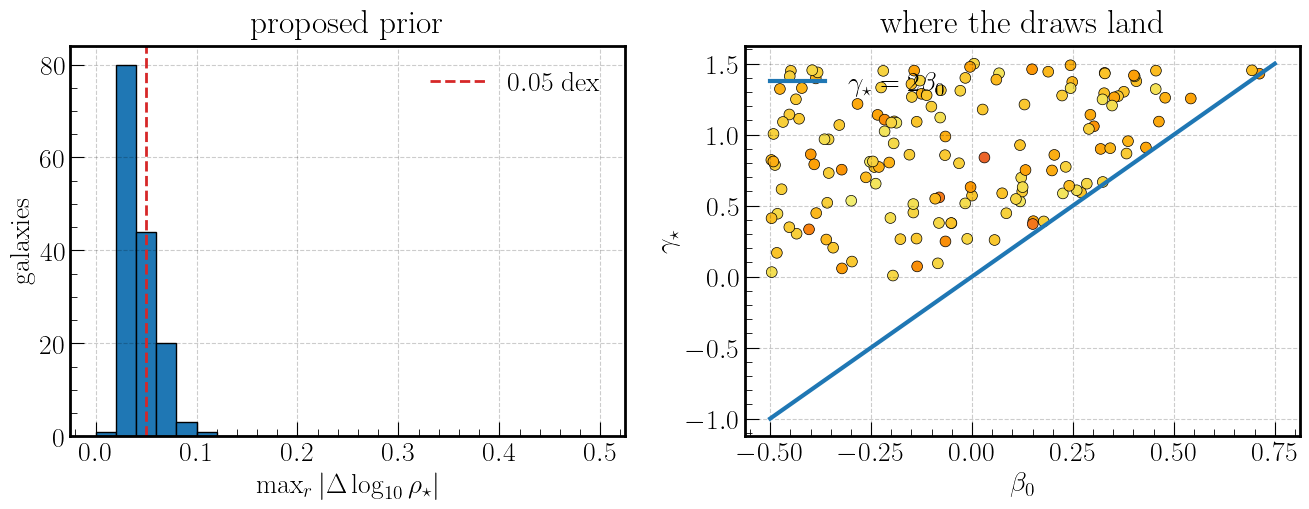

median error 0.039 dex, 90th pct 0.064 dex, max 0.104 dex


In [11]:
def label_error(params: np.ndarray, n_samp: int = 40000) -> float:
    """
    Deviation between the sampled and the labelled tracer profile.

    Args:
        params: Array of 11 model parameters.
        n_samp: Number of stars to sample.

    Returns:
        max |dlog10 rho| over well-populated radial bins, or NaN if the
        model could not be built.
    """
    posvel = simulator_11(n_samp, params)
    if posvel is None:
        return np.nan
    r_star = 10 ** params[7] * 10 ** params[3]
    dens = abg_density(params[8], params[9], params[10], r_s=r_star)
    edges = np.logspace(np.log10(r_star) - 1.5, np.log10(r_star) + 1.0, 22)
    cen = np.sqrt(edges[1:] * edges[:-1])
    vol = 4 * np.pi / 3 * (edges[1:] ** 3 - edges[:-1] ** 3)
    counts, _ = np.histogram(np.linalg.norm(posvel[:, :3], axis=1),
                             bins=edges)
    rho_s = counts / n_samp / vol
    rho_i = dens.density(
        np.column_stack([cen, np.zeros_like(cen), np.zeros_like(cen)]))
    ok = counts > 100
    if ok.sum() < 5:
        return np.nan
    return np.max(np.abs(np.log10(rho_s[ok] / rho_i[ok])))


t0 = time.time()
draws = [draw_prior(RNG) for _ in range(150)]
errs = np.array([label_error(p, n_samp=30000) for p in draws])
print(f'{time.time() - t0:.0f}s; {np.sum(np.isnan(errs))} failed to build')

valid = errs[np.isfinite(errs)]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
axes[0].hist(valid, bins=np.linspace(0, 0.5, 26), color='C0',
             edgecolor='k')
axes[0].axvline(0.05, color='C3', ls='--', lw=2, label=r'$0.05$ dex')
axes[0].set_xlabel(r'$\max_r |\Delta\log_{10}\rho_\star|$')
axes[0].set_ylabel('galaxies')
axes[0].legend()
axes[0].set_title('proposed prior')

good = np.isfinite(errs)
axes[1].scatter(np.array([p[I_BETA0] for p in draws])[good],
                np.array([p[I_GAMMA_STAR] for p in draws])[good],
                c=valid, cmap='inferno_r', vmin=0, vmax=0.3,
                s=60, edgecolor='k', linewidth=0.5)
bb = np.linspace(-0.5, 0.75, 50)
axes[1].plot(bb, 2 * bb, 'C0-', lw=3, label=r'$\gamma_\star = 2\beta_0$')
axes[1].set_xlabel(r'$\beta_0$')
axes[1].set_ylabel(r'$\gamma_\star$')
axes[1].legend(loc='upper left')
axes[1].set_title('where the draws land')
fig.tight_layout()
fig.savefig(f'{OUTDIR}/fig8_prior_validation.png', dpi=140,
            bbox_inches='tight')
plt.show()

print(f'median error {np.median(valid):.3f} dex, '
      f'90th pct {np.percentile(valid, 90):.3f} dex, '
      f'max {valid.max():.3f} dex')

Every accepted draw sits on or above the constraint line, and the bulk of
the distribution sits near 0.04 dex — consistent with Poisson noise from
the 30 000-star test sample rather than model error.

The tail is the interesting part. A handful of draws land well above
0.1 dex *despite* satisfying $\gamma_\star \geq 2\beta_0$, and in the
right-hand panel they are not concentrated near the constraint line — so
the $\gamma_\star$–$\beta_0$ cut is not the whole story. The next section
tracks them down.

## 8b. Consistency check G — what explains the residual tail?

Rather than guess, correlate the label error against every parameter and
let the data name the culprit.

In [12]:
from scipy.stats import spearmanr


def draw_prior_ra(rng: np.random.Generator, log_ra_min: float) -> np.ndarray:
    """
    Draw from the prior with an adjustable lower bound on log10(r_a).

    Args:
        rng: Random number generator.
        log_ra_min: Lower edge of the log10(r_a / a_star) prior. The old
            pipeline value is -1; this notebook proposes 0.

    Returns:
        Array of 11 model parameters with gamma_star >= 2 * beta0.
    """
    lo = PRIOR_MIN_11.copy()
    lo[6] = log_ra_min
    while True:
        params = rng.uniform(lo, PRIOR_MAX_11)
        if params[I_GAMMA_STAR] >= 2 * params[I_BETA0]:
            return params


def prior_scan(log_ra_min: float, n: int = 250,
               n_samp: int = 25000) -> tuple[np.ndarray, np.ndarray]:
    """
    Draw from the prior and measure the label error for each draw.

    Args:
        log_ra_min: Lower edge of the log10(r_a / a_star) prior.
        n: Number of draws.
        n_samp: Stars sampled per draw.

    Returns:
        Tuple of (parameters of shape (m, 11), errors) for usable draws.
    """
    par = np.array([draw_prior_ra(RNG, log_ra_min) for _ in range(n)])
    err = np.array([label_error(p, n_samp=n_samp) for p in par])
    ok = np.isfinite(err)
    return par[ok], err[ok]


t0 = time.time()
# "Before": the pipeline's original log_ra range. "After": the proposed cut.
par_wide, err_wide = prior_scan(-1.0)
par_narrow, err_narrow = prior_scan(0.0)
print(f'{time.time() - t0:.0f}s')
for tag, e in [('log_ra >= -1 (original)', err_wide),
               ('log_ra >=  0 (proposed)', err_narrow)]:
    print(f'  {tag}: n={len(e)}  median {np.median(e):.3f}  '
          f'90th {np.percentile(e, 90):.3f}  max {e.max():.3f} dex')

print('\nSpearman correlation of label error with each parameter '
      '(original prior):')
rows = []
for i, name in enumerate(PARAM_NAMES_11):
    rho, pval = spearmanr(par_wide[:, i], err_wide)
    rows.append((name, rho, pval))
    flag = '   <<<' if pval < 0.01 else ''
    print(f'  {name:20s} rho = {rho:+.3f}   p = {pval:.1e}{flag}')

# Margin to the gamma_star = 2 beta0 line, for comparison.
margin = par_wide[:, I_GAMMA_STAR] - 2 * par_wide[:, I_BETA0]
rho_m, p_m = spearmanr(margin, err_wide)
print(f'  {"margin to constraint":20s} rho = {rho_m:+.3f}   p = {p_m:.1e}'
      f'{"   <<<" if p_m < 0.01 else ""}')

92s
  log_ra >= -1 (original): n=246  median 0.041  90th 0.085  max 0.934 dex
  log_ra >=  0 (proposed): n=241  median 0.044  90th 0.071  max 0.143 dex

Spearman correlation of label error with each parameter (original prior):
  dm_alpha             rho = -0.044   p = 4.9e-01
  dm_beta              rho = +0.021   p = 7.4e-01
  dm_gamma             rho = +0.089   p = 1.7e-01
  dm_log_rdm           rho = -0.103   p = 1.1e-01
  dm_log_rho0          rho = -0.007   p = 9.2e-01
  df_beta0             rho = +0.059   p = 3.5e-01
  df_log_ra            rho = -0.262   p = 3.1e-05   <<<
  stellar_log_rstar    rho = +0.020   p = 7.5e-01
  stellar_alpha        rho = -0.106   p = 9.9e-02
  stellar_beta         rho = -0.098   p = 1.3e-01
  stellar_gamma        rho = +0.074   p = 2.5e-01
  margin to constraint rho = -0.011   p = 8.6e-01


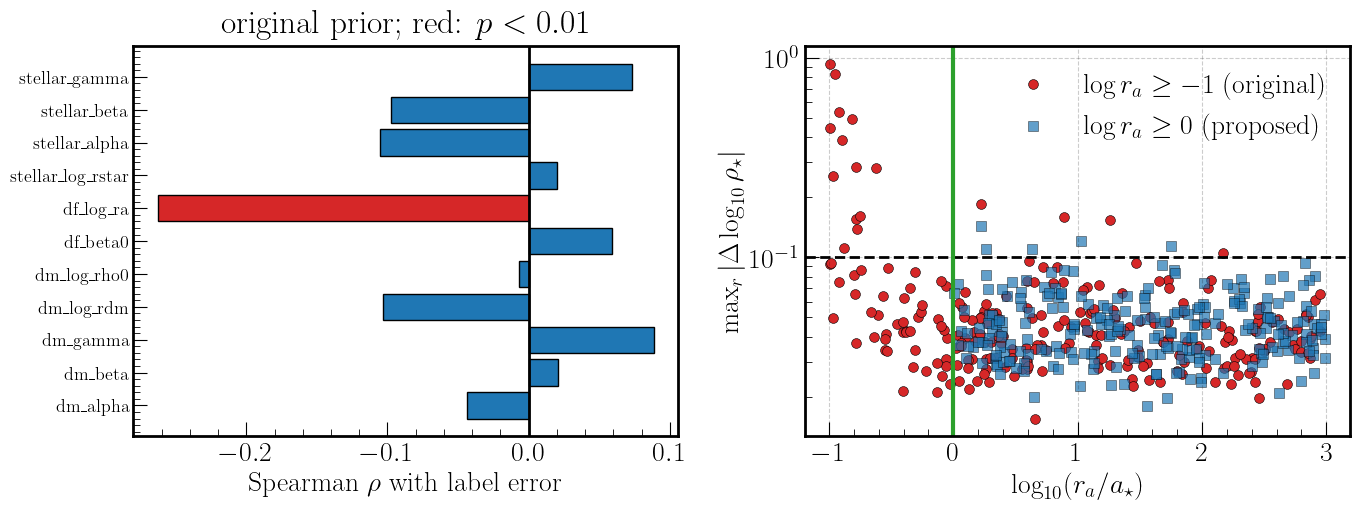

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
names, rhos, pvals = zip(*rows)
colors = ['C3' if p < 0.01 else 'C0' for p in pvals]
ypos = np.arange(len(names))
axes[0].barh(ypos, rhos, color=colors, edgecolor='k')
axes[0].set_yticks(ypos)
axes[0].set_yticklabels([n.replace('_', r'\_') for n in names], fontsize=13)
axes[0].axvline(0, color='k', lw=2)
axes[0].set_xlabel(r'Spearman $\rho$ with label error')
axes[0].set_title(r'original prior; red: $p < 0.01$')
axes[0].grid(False)

axes[1].scatter(par_wide[:, 6], err_wide, s=50, c='C3', edgecolor='k',
                linewidth=0.4, label=r'$\log r_a \geq -1$ (original)')
axes[1].scatter(par_narrow[:, 6], err_narrow, s=50, c='C0', marker='s',
                edgecolor='k', linewidth=0.4, alpha=0.7,
                label=r'$\log r_a \geq 0$ (proposed)')
axes[1].axhline(0.1, color='k', ls='--', lw=2)
axes[1].axvline(0.0, color='C2', ls='-', lw=3)
axes[1].set_xlabel(r'$\log_{10}(r_a / a_\star)$')
axes[1].set_ylabel(r'$\max_r |\Delta\log_{10}\rho_\star|$')
axes[1].set_yscale('log')
axes[1].legend(loc='upper right')
fig.tight_layout()
fig.savefig(f'{OUTDIR}/fig9_ra_diagnosis.png', dpi=140, bbox_inches='tight')
plt.show()

**$r_a$ is the culprit, and nothing else is.** Over the original
$\log r_a \in [-1, 3]$ box it is the only parameter with a significant
correlation (red bar, left panel). Crucially the *margin* to the
$\gamma_\star = 2\beta_0$ line is **not** correlated, which rules out the
soft-boundary explanation — the failures are not draws that squeaked past
the cut, they are draws with a small anisotropy radius.

The right panel is the before/after. Every high-error point in the
original prior (red) sits at $\log r_a \lesssim 0$; restricting to
$\log r_a \geq 0$ (blue) removes them. The worst-case label error drops
by roughly a factor of five (exact values in the printout above; the
median barely moves, because the cut removes a tail rather than shifting
the bulk).

The physics: $\gamma_\star \geq 2\beta_0$ is the theorem evaluated *at the
centre*. The Osipkov–Merritt profile has $\beta(r) \to 1$ for
$r \gg r_a$, so the local inequality $\gamma(r) \geq 2\beta(r)$ has to
hold at every radius. Because the pipeline specifies $r_a$ **in units of
$a_\star$**, the old lower bound $\log r_a = -1$ allowed
$r_a = 0.1\,a_\star$ — the tracer goes fully radial well inside its own
half-light radius, where the local density slope is still shallow, and
the inversion truncates there. That bound is adopted in `PRIOR_MIN_11`
above.

## 8c. This already affects the existing 8-parameter PRIOR_A

The Plummer tracer has $\gamma_\star = 0$, so the central form of the
theorem requires $\beta_0 \leq 0$ — yet PRIOR_A draws
$\beta_0 \in [-0.499, 1.0]$. Two thirds of that range is in the violated
region. Since this notebook has the machinery, it is worth measuring
rather than assuming.

In [14]:
PRIOR_MIN_8 = np.array([0.5, 1.0, -1.0, -2.0, 3.0, -0.499, -1.0, -3.0])
PRIOR_MAX_8 = np.array([3.0, 10.0, 2.0, 2.0, 10.0, 1.0, 3.0, 0.0])


def label_error_8(params: np.ndarray, n_samp: int = 25000) -> float:
    """
    Label error for the existing 8-parameter Plummer simulator.

    Reproduces `simulator()` from simulate_8params_process_priorA.py
    exactly, then compares the sampled stellar density to the Plummer
    profile the labels claim.

    Args:
        params: Array of 8 model parameters.
        n_samp: Number of stars to sample.

    Returns:
        max |dlog10 rho| over well-populated bins, or NaN on failure.
    """
    alpha, beta, gamma, log_rdm, log_rhos, beta0, log_ra, log_rstar = params
    r_dm = 10 ** log_rdm
    r_star = 10 ** log_rstar * r_dm
    r_a = 10 ** log_ra * r_star
    try:
        pot = agama.Potential(
            type='Spheroid', alpha=alpha, beta=beta, gamma=gamma,
            scaleRadius=r_dm, densityNorm=10 ** log_rhos,
            outercutoffRadius=max(50, 10 * r_dm))
        dens = agama.Density(type='Plummer', mass=1, scaleRadius=r_star)
        df = agama.DistributionFunction(
            type='QuasiSpherical', potential=pot, density=dens,
            beta0=beta0, r_a=r_a)
        posvel, _ = agama.GalaxyModel(pot, df).sample(n_samp)
    except Exception:
        return np.nan
    edges = np.logspace(np.log10(r_star) - 1.5, np.log10(r_star) + 1.0, 22)
    cen = np.sqrt(edges[1:] * edges[:-1])
    vol = 4 * np.pi / 3 * (edges[1:] ** 3 - edges[:-1] ** 3)
    counts, _ = np.histogram(np.linalg.norm(posvel[:, :3], axis=1),
                             bins=edges)
    rho_s = counts / n_samp / vol
    rho_i = dens.density(
        np.column_stack([cen, np.zeros_like(cen), np.zeros_like(cen)]))
    ok_bins = counts > 100
    if ok_bins.sum() < 5:
        return np.nan
    return np.max(np.abs(np.log10(rho_s[ok_bins] / rho_i[ok_bins])))


t0 = time.time()
draws_8 = RNG.uniform(PRIOR_MIN_8, PRIOR_MAX_8, size=(320, 8))
errs_8 = np.array([label_error_8(p) for p in draws_8])
ok8 = np.isfinite(errs_8)
print(f'{time.time() - t0:.0f}s; {ok8.sum()}/320 built successfully')
print(f'median {np.median(errs_8[ok8]):.3f} dex, '
      f'90th pct {np.percentile(errs_8[ok8], 90):.3f} dex, '
      f'max {errs_8[ok8].max():.3f} dex')

110s; 299/320 built successfully
median 0.158 dex, 90th pct 0.829 dex, max 2.922 dex


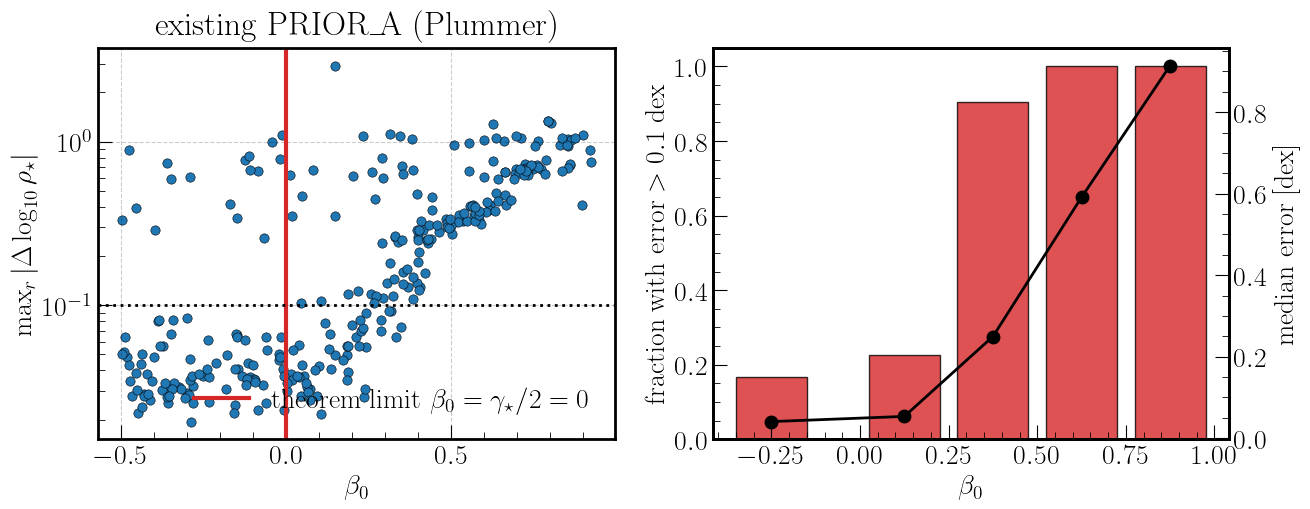

  beta0 in [-0.50, +0.00): median 0.041 dex, 17% above 0.1 dex
  beta0 in [+0.00, +0.25): median 0.053 dex, 23% above 0.1 dex
  beta0 in [+0.25, +0.50): median 0.250 dex, 90% above 0.1 dex
  beta0 in [+0.50, +0.75): median 0.591 dex, 100% above 0.1 dex
  beta0 in [+0.75, +1.00): median 0.914 dex, 100% above 0.1 dex


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
axes[0].scatter(draws_8[ok8, 5], errs_8[ok8], s=45, c='C0',
                edgecolor='k', linewidth=0.4)
axes[0].axvline(0.0, color='C3', lw=3,
                label=r'theorem limit $\beta_0 = \gamma_\star/2 = 0$')
axes[0].axhline(0.1, color='k', ls=':', lw=2)
axes[0].set_yscale('log')
axes[0].set_xlabel(r'$\beta_0$')
axes[0].set_ylabel(r'$\max_r |\Delta\log_{10}\rho_\star|$')
axes[0].set_title('existing PRIOR\\_A (Plummer)')
axes[0].legend(loc='lower right')

bins_b0 = [(-0.5, 0.0), (0.0, 0.25), (0.25, 0.5), (0.5, 0.75), (0.75, 1.0)]
frac, med, ctr = [], [], []
for lo, hi in bins_b0:
    sel = ok8 & (draws_8[:, 5] >= lo) & (draws_8[:, 5] < hi)
    if sel.sum() < 3:
        continue
    frac.append(np.mean(errs_8[sel] > 0.1))
    med.append(np.median(errs_8[sel]))
    ctr.append(0.5 * (lo + hi))
axes[1].bar(ctr, frac, width=0.2, color='C3', edgecolor='k', alpha=0.8)
axes[1].set_xlabel(r'$\beta_0$')
axes[1].set_ylabel(r'fraction with error $> 0.1$ dex')
axes[1].set_ylim(0, 1.05)
axes[1].grid(False)
ax2 = axes[1].twinx()
ax2.plot(ctr, med, 'ko-', lw=2, ms=9)
ax2.set_ylabel(r'median error [dex]')
ax2.grid(False)
fig.tight_layout()
fig.savefig(f'{OUTDIR}/fig10_prior_a_audit.png', dpi=140,
            bbox_inches='tight')
plt.show()

for (lo, hi), f, m in zip(bins_b0, frac, med):
    print(f'  beta0 in [{lo:+.2f}, {hi:+.2f}): median {m:.3f} dex, '
          f'{100 * f:.0f}% above 0.1 dex')

### What this does and does not mean

The measurement is unambiguous, and the $\beta_0$ breakdown is the stable
way to read it (the overall median depends on how wide the $\beta_0$ prior
is). For $\beta_0 < 0$ — the region the theorem allows — the median error
sits at the few-hundredths-of-a-dex noise floor. Above $\beta_0 = 0.5$
essentially **every** galaxy exceeds 0.1 dex, and the median error climbs
monotonically through the upper bins to of order a decade. Since
$\beta_0$ is drawn uniformly on $[-0.499, 1.0]$, roughly half of PRIOR_A
lands in the affected region. Read the exact per-bin numbers off the
printout above rather than from this text.

The residual $\approx 20\%$ of low-$\beta_0$ galaxies above 0.1 dex are
the $r_a$ effect of section 8b — PRIOR_A also allows
$\log r_a \geq -1$.

**This is not a bug that invalidates existing posteriors.** NPE learns
$p(\theta \mid x)$ from $(\theta, x)$ pairs, and those pairs are
internally consistent: the data really were generated at those $\theta$.
A posterior trained this way is a correct posterior *for this simulator*.

**What it does break is the interpretation of the parameters.** For
$\beta_0 > 0$ the tracer is not a Plummer sphere, so $a_\star$ is no
longer "the Plummer scale radius of the stellar distribution" and
$\beta_0$ is no longer the realised anisotropy. They are labels for a
truncated-DF model that happens to be parametrised that way. The moment
the posterior is compared against a real dSph — whose light profile *is*
measured, and *is* roughly Plummer — the mismatch becomes a systematic.

Worth deciding deliberately, not inheriting by accident. The same
$\gamma_\star \geq 2\beta_0$ cut fixes it for the Plummer case too: with
$\gamma_\star = 0$ it simply means capping $\beta_0$ at 0, which is a real
loss of prior range — and the stronger argument for moving to the
$\alpha\beta\gamma$ tracer, where $\gamma_\star > 0$ buys back radial
anisotropy legitimately.

## Summary

* **Plummer $=$ Spheroid$(2, 5, 0)$ exactly**, including normalisation.
  The extension is a strict superset; nothing about the old prior changes
  meaning.
* **The slope–anisotropy theorem is a hard prior constraint, not a
  guideline.** Violating it corrupts the training labels by up to a decade
  in density, silently, with no exception raised. Enforce
  $\gamma_\star \geq 2\beta_0$ at draw time. This is the finding to act on.
* The DM inner slope does not move that boundary anywhere in PRIOR_A, so
  the central cut suffices — but **$r_a$ needs its own bound**. The
  theorem's local form is violated when $r_a \ll a_\star$; requiring
  $r_a \geq a_\star$ cuts the worst-case label error by about a factor
  of five (section 8b).
* **The existing 8-parameter PRIOR_A is already affected** (section 8c):
  Plummer has $\gamma_\star = 0$, so $\beta_0 > 0$ violates the theorem,
  and essentially every galaxy with $\beta_0 > 0.5$ misses its Plummer
  label by more than 0.1 dex, with medians of order a decade at the top of
  the range. This does not invalidate existing posteriors — the
  $(\theta, x)$ pairs are self-consistent — but it does mean $a_\star$
  and $\beta_0$ do not mean what their names say for $\beta_0 > 0$,
  which matters as soon as the posterior meets a real dwarf.
* Use `mass=1`, not `densityNorm=`, for the tracer, so the shape
  parameters do not couple to the normalisation.
* **Save the projected half-light radius $R_h$** as an extra label:
  $R_h/a_\star$ ranges over an order of magnitude across the prior, and
  $R_h$ is the direction the posterior will actually be sharp in.
* Cost is unchanged from the Plummer version (a few ms per galaxy), so
  this extension is essentially free compared with experiment 1.